In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Sobre el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (semanas) se adjunta, responda al cuestionario. Cada pregunta tiene una sola respuesta correcta. Al final se pide generar el cuestionario en formato GIFT para importarlo en Moodle.

In [4]:
pregunta_1 = "1. ¿Cuál es la duración del proyecto?  "
pregunta_2 = "2. ¿Cuál es la holgura total de D?  "
pregunta_3 = "3. ¿Cuántas rutas tiene el grafo (del nodo inicial al final, sin contar ficticias como actividades)?  "
pregunta_4 = "4. ¿Cuántas actividades ficticias necesita el grafo PERT con el mínimo número de ellas?  "
pregunta_5 = "5. ¿Cuál es, aproximadamente, la probabilidad de terminar en 37 semanas o menos (aproximación normal por el camino crítico)?  "
pregunta_6 = "6. Genere el fichero GIFT con las cinco preguntas, sus opciones y la retroalimentación.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. ¿Cuál es la duración del proyecto?  

2. ¿Cuál es la holgura total de D?  

3. ¿Cuántas rutas tiene el grafo (del nodo inicial al final, sin contar ficticias como actividades)?  

4. ¿Cuántas actividades ficticias necesita el grafo PERT con el mínimo número de ellas?  

5. ¿Cuál es, aproximadamente, la probabilidad de terminar en 37 semanas o menos (aproximación normal por el camino crítico)?  

6. Genere el fichero GIFT con las cinco preguntas, sus opciones y la retroalimentación.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 6       , 0.2               ),
    ('B'     , '---'      , 5       , 0.2               ),
    ('C'     , 'A,B'      , 6       , 0.4               ),
    ('D'     , 'A'        , 2       , 0.4               ),
    ('E'     , 'C,D'      , 4       , 0.3               ),
    ('F'     , 'E'        , 6       , 0.4               ),
    ('G'     , 'E'        , 8       , 0.4               ),
    ('H'     , 'F,G'      , 4       , 0.6               ),
    ('I'     , 'H'        , 7       , 0.2               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,6,0.2
B,---,5,0.2
C,"A,B",6,0.4
D,A,2,0.4
E,"C,D",4,0.3
F,E,6,0.4
G,E,8,0.4
H,"F,G",4,0.6
I,H,7,0.2


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
R = proyecto.path_matrix(dummies=False)
sigma, _ = proyecto.standard_deviation(durations=datos_proyecto['duration'], variances=datos_proyecto['variance'])
X, plazo = 'D', 37
p_plazo = float(norm.cdf((plazo - duracion) / sigma))

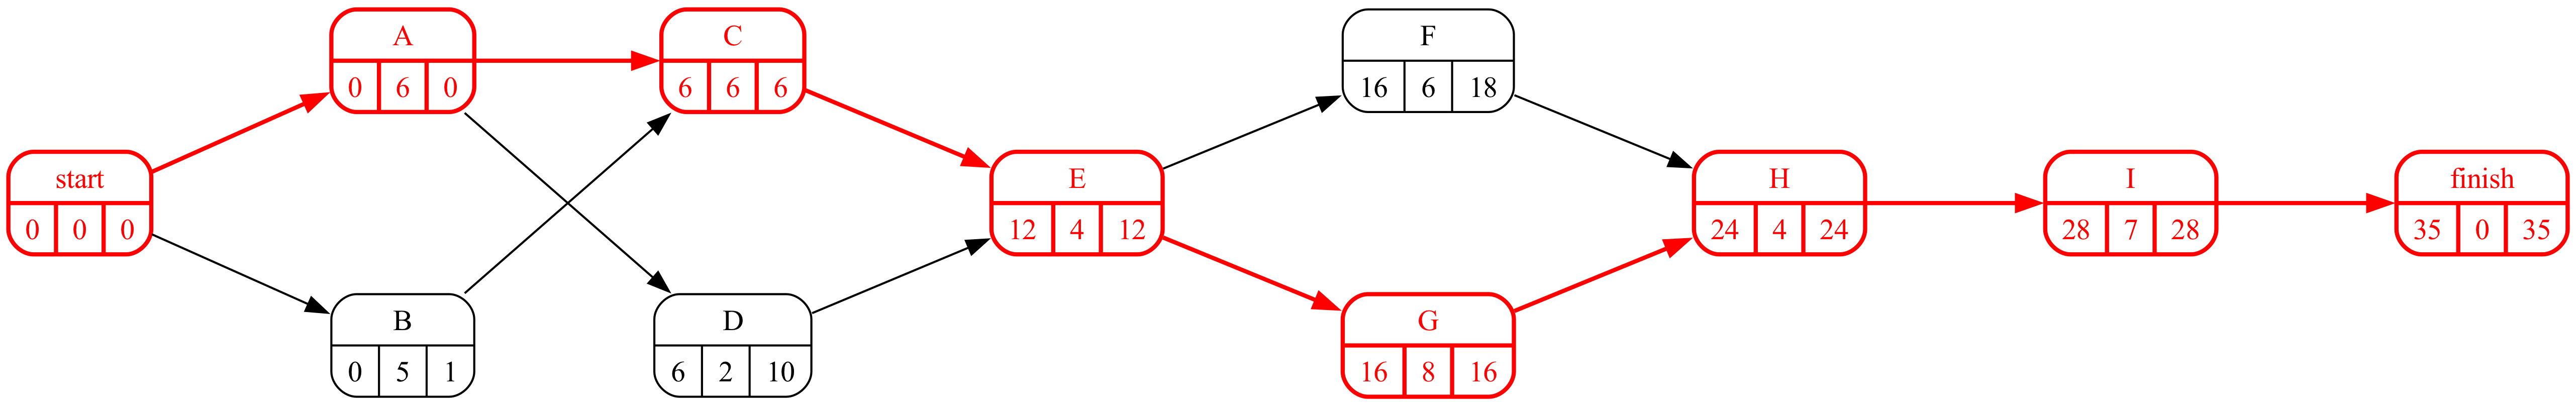

In [7]:
#| fig-cap: "Grafo Roy con el camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [ ]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

Cada pregunta se construye con la respuesta correcta calculada y tres distractores *plausibles*: errores típicos (sumar todas las duraciones, confundir holgura libre y total, contar las ficticias como rutas, usar la varianza en lugar de la desviación…).

In [8]:
h_total, h_libre = int(calendario.loc[X, 'H_total']), int(calendario.loc[X, 'H_libre'])
n_rutas, n_fict = len(R), len(proyecto.dummies)
p_mal = float(norm.cdf((plazo - duracion) / sigma ** 2))
def opciones(correcta, distractores):
    vistos, lista = set(), []
    for v in [correcta] + distractores:
        if v not in vistos:
            vistos.add(v); lista.append(v)
    return lista[:4]
preguntas_test = [
    ('¿Cuál es la duración del proyecto (semanas)?', opciones(duracion, [int(datos_proyecto['duration'].sum()), duracion - 1, duracion + 2, duracion + 1, duracion - 2]),
     'La duración es la de la ruta más larga, no la suma de todas las actividades.'),
    (f'¿Cuál es la holgura total de {X} (semanas)?', opciones(h_total, [h_libre, 0, h_total + 2, h_total + 1, h_total + 3]),
     'H_total = inicio más tardío − inicio más temprano; la holgura libre puede ser menor.'),
    ('¿Cuántas rutas tiene el grafo del nodo inicial al final?', opciones(n_rutas, [n_rutas + n_fict, n_rutas - 1, n_rutas + 2, n_rutas + 1, n_rutas + 3]),
     'Las ficticias no añaden rutas distintas en términos de actividades.'),
    ('¿Cuántas actividades ficticias necesita el PERT con el mínimo número de ellas?', opciones(n_fict, [0, n_fict + 1, n_fict + 2, n_fict + 3]),
     'Hacen falta ficticias cuando dos actividades comparten parte de sus predecesoras o irían entre los mismos nodos.'),
    (f'¿Probabilidad aproximada de terminar en {plazo} semanas o menos?', opciones(round(p_plazo, 2), [round(p_mal, 2), 0.5, round(1 - p_plazo, 2), 0.95, round(p_plazo / 2, 2)]),
     'z = (plazo − duración) / σ, con σ la desviación típica de la ruta crítica (raíz de la suma de varianzas).'),
]
for i, (q, ops, fb) in enumerate(preguntas_test, 1):
    print(f'{i}. {q}  →  correcta: {ops[0]}   (opciones: {ops})')

1. ¿Cuál es la duración del proyecto (semanas)?  →  correcta: 35   (opciones: [35, 48, 34, 37])
2. ¿Cuál es la holgura total de D (semanas)?  →  correcta: 4   (opciones: [4, 0, 6, 5])
3. ¿Cuántas rutas tiene el grafo del nodo inicial al final?  →  correcta: 6   (opciones: [6, 8, 5, 7])
4. ¿Cuántas actividades ficticias necesita el PERT con el mínimo número de ellas?  →  correcta: 2   (opciones: [2, 0, 3, 4])
5. ¿Probabilidad aproximada de terminar en 37 semanas o menos?  →  correcta: 0.98   (opciones: [0.98, 0.99, 0.5, 0.02])


## Apartado 6

In [9]:
display(Markdown(pregunta_6))

6. Genere el fichero GIFT con las cinco preguntas, sus opciones y la retroalimentación.  

El formato GIFT de Moodle escribe cada pregunta como `::título::texto {=correcta ~incorrecta ~incorrecta #retroalimentación}`. Las opciones se barajan al generar el fichero.

In [10]:
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta, resto = ops[0], ops[1:]
        orden = list(r.permutation(len(ops)))
        todas = [ops[j] for j in orden]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Proyecto test')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Proyecto test

::Proyecto test P1::¿Cuál es la duración del proyecto (semanas)? {=35 ~48 ~34 ~37 ####La duración es la de la ruta más larga, no la suma de todas las actividades.}

::Proyecto test P2::¿Cuál es la holgura total de D (semanas)? {~5 =4 ~6 ~0 ####H_total = inicio más tardío − inicio más temprano; la holgura libre puede ser menor.}

::Proyecto test P3::¿Cuántas rutas tiene el grafo del nodo inicial al final? {~7 =6 ~8 ~5 ####Las ficticias no añaden rutas distintas en términos de actividades.}

::Proyecto test P4::¿Cuántas actividades ficticias necesita el PERT con el mínimo número de ellas? {~3 ~4 ~0 =2 ####Hacen falta ficticias cuando dos actividades comparten parte de sus predecesoras o irían entre los mismos nodos.}

::Proyecto test P5::¿Probabilidad aproximada de terminar en 37 semanas o menos? {~0.99 =0.98 ~0.5 ~0.02 ####z = (plazo − duración) / σ, con σ la desviación típica de la ruta crítica (raíz de la suma de varianzas).}

